In [1]:
import sys, time
sys.path.insert(0, "../examples")
import numpy as np, jax, jax.numpy as jnp, scipy.optimize
import matplotlib.pyplot as plt
import gebtaero_jax as gx
from hale_wings import EcoHALEWing, DawnWing, trim_alpha, G0

eco = EcoHALEWing(12); x_eco = eco.baseline()
dawn = DawnWing(12, batteries="fuselage"); t_dawn = dawn.sized_spar()

## 1. Models and mass closure

In [2]:
m_eco, _ = eco.build(x_eco, aero=gx.Aero.NONE)
m_daw, _ = dawn.build(t_dawn, aero=gx.Aero.NONE)
on_eco = float(jnp.sum(m_eco.mass[:, 0, 0] * m_eco.dL)) * 2
bud = dawn.mass_budget(t_dawn)
print("EcoHALE                          published     model")
print(f"  span / root chord / taper       55.6/1.40/0.30  {eco.SPAN}/{eco.C_ROOT}/{eco.TAPER}")
print(f"  wing area [m2]                  50.6            {2 * eco.area_half:.1f}")
print(f"  wingbox mass [kg]               82.4            {float(eco.structural_mass(x_eco)):.1f}")
print(f"  mass on the wing [kg]           (82.4+116.7+motors)  {on_eco:.1f}  (motors {eco.motor_mass} kg each, at the tips)")
print(f"  skin root/tip [mm], spars [mm]  not reported    {1e3 * float(x_eco[0]):.2f}/{1e3 * float(x_eco[eco.n - 1]):.2f}, {1e3 * float(x_eco[eco.n]):.1f}")
print(f"  t/c root/tip                    not reported    {eco.TC_ROOT:.3f}/{eco.TC_TIP:.3f} (calibrated, see §3)")
print("\nDawn                             published     model")
print(f"  span / area / AR                39.9/67.9/23.4  {dawn.SPAN}/{dawn.AREA}/{dawn.SPAN**2 / dawn.AREA:.1f}")
print(f"  root chord [m] (break 67 %, taper 0.5)          {dawn.c_root:.3f}")
print(f"  TOGW [kg]                       375             {dawn.TOGW}")
print("  on-wing masses [kg]:", {k: round(v, 1) for k, v in bud.items()})
print(f"  spar wall root -> tip [mm]: {np.round(np.asarray(t_dawn) * 1e3, 2)}  (3 g ultimate, CFRP tube, 0.6 mm min gauge)")
print(f"  density at {dawn.ALTITUDE / 1e3:.1f} km: {dawn.rho:.4f} kg/m3;  CL check: {dawn.TOGW * G0 / (0.5 * dawn.rho * dawn.V_CRUISE**2 * dawn.AREA):.3f} (paper 1.106-1.113)")

EcoHALE                          published     model
  span / root chord / taper       55.6/1.40/0.30  55.6/1.4/0.3
  wing area [m2]                  50.6            50.6
  wingbox mass [kg]               82.4            82.4
  mass on the wing [kg]           (82.4+116.7+motors)  211.1  (motors 6.0 kg each, at the tips)
  skin root/tip [mm], spars [mm]  not reported    3.81/1.41, 1.0
  t/c root/tip                    not reported    0.225/0.190 (calibrated, see §3)

Dawn                             published     model
  span / area / AR                39.9/67.9/23.4  39.9/67.9/23.4
  root chord [m] (break 67 %, taper 0.5)          1.855
  TOGW [kg]                       375             375.0
  on-wing masses [kg]: {'spar': 61.2, 'secondary': 37.3, 'solar': 21.7, 'batteries_in_wing': 0.0, 'booms': 36.0, 'on_wing': 156.3, 'fuselage_and_rest': 218.7}
  spar wall root -> tip [mm]: [3.9  3.21 2.58 2.02 1.54 1.12 0.77 0.6  0.6  0.6  0.6  0.6 ]  (3 g ultimate, CFRP tube, 0.6 mm min gauge)
  d

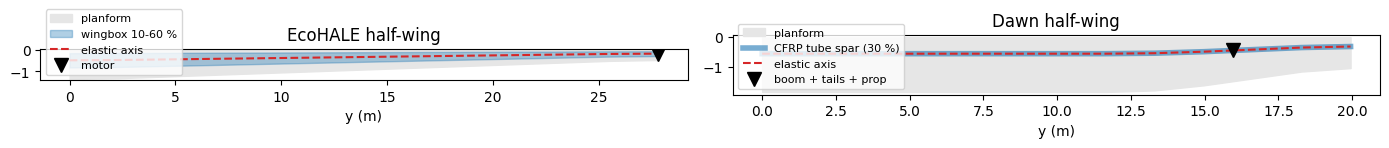

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, w, title, pm in [(axs[0], eco, "EcoHALE half-wing", [(eco.SPAN / 2, "motor")]),
                         (axs[1], dawn, "Dawn half-wing", [(dawn.BOOM_ETA * dawn.SPAN / 2, "boom + tails + prop")])]:
    ye = (np.arange(w.n + 1)) * w.dy
    c = np.interp(ye, w.eta * w.SPAN / 2, w.chord)
    xea = getattr(w, "X_EA", getattr(w, "X_SPAR", 0.3))
    ax.fill_between(ye, -(0 * c), -c, color="0.9", label="planform")
    if w is eco:
        ax.fill_between(ye, -0.10 * c, -0.60 * c, color="C0", alpha=0.35, label="wingbox 10-60 %")
    else:
        ax.plot(ye, -0.30 * c, color="C0", lw=4, alpha=0.6, label="CFRP tube spar (30 %)")
    ax.plot(ye, -xea * c, "C3--", label="elastic axis")
    for s, lab in pm:
        ax.plot(s, -xea * np.interp(s, ye, c), "kv", ms=10, label=lab)
    ax.set_aspect("equal"); ax.set_xlabel("y (m)"); ax.set_title(title); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()

## 2. In-vacuo modes

EcoHALE modes [Hz]: [ 0.593  1.022  2.271  4.069  5.975 10.788]
Dawn    modes [Hz]: [ 0.725  3.635  4.07   4.233 10.326 19.613]


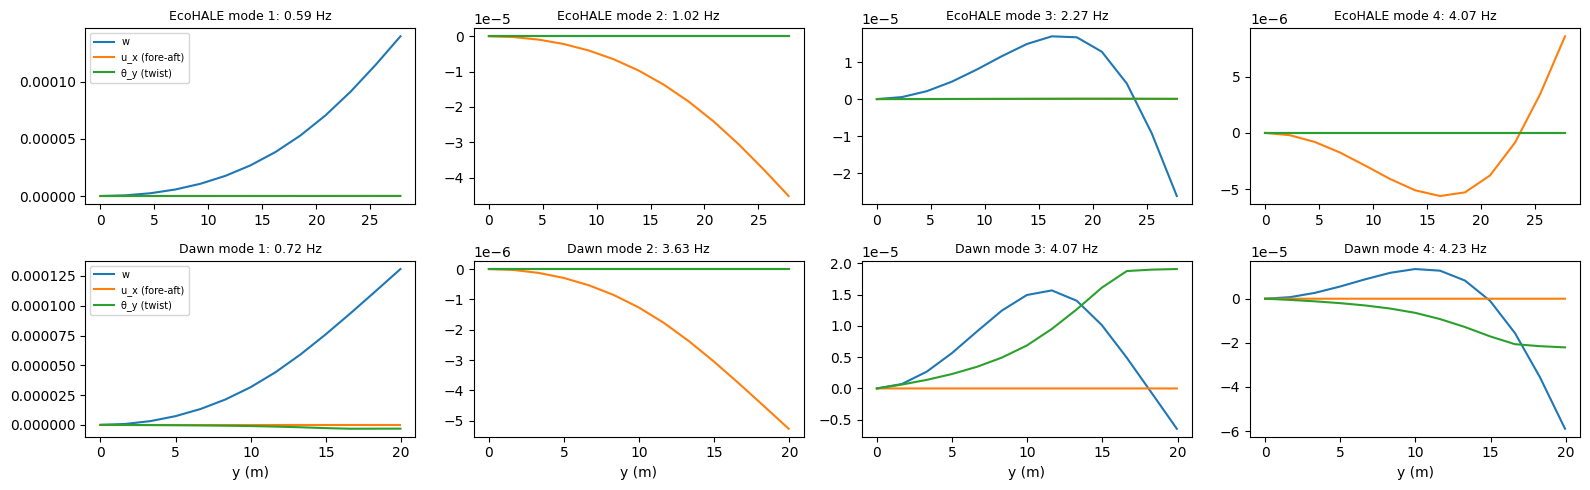

In [4]:
res_e = gx.modal_analysis(m_eco, gx.FlightCondition()); res_d = gx.modal_analysis(m_daw, gx.FlightCondition())
print("EcoHALE modes [Hz]:", np.round(res_e.table(6)[:, 1], 3))
print("Dawn    modes [Hz]:", np.round(res_d.table(6)[:, 1], 3))
fig, axs = plt.subplots(2, 4, figsize=(16, 5), sharex="row")
for row, (m, r, name) in enumerate([(m_eco, res_e, "EcoHALE"), (m_daw, res_d, "Dawn")]):
    y = np.asarray(gx.node_positions(m))[:, 1]
    for k, ax in enumerate(axs[row]):
        u, th = gx.mode_shape(m, r.right[:, r.oscillatory()[k]])
        ax.plot(y, u[:, 2], label="w"); ax.plot(y, u[:, 0], label="u_x (fore-aft)"); ax.plot(y, th[:, 1], label="θ_y (twist)")
        ax.set_title(f"{name} mode {k + 1}: {r.freq_hz[r.oscillatory()[k]]:.2f} Hz", fontsize=9)
    axs[row, 0].legend(fontsize=7)
for ax in axs[1]: ax.set_xlabel("y (m)")
plt.tight_layout()

## 3. Trimmed nonlinear static aeroelasticity
Each half-wing is trimmed (root angle of attack by Newton, derivative by AD through the nonlinear equilibrium) so that its lift balances its own
weight plus half of the mass carried at the root (fuselage, payload, batteries for Dawn). Load cases:

* **EcoHALE gust point** (from the notebook): $V_D = 1.4V = 48.3$ m/s, $n = 1.1$, gust incidence $\arctan(3.4/V_D) = 4.0°$ on top of the cruise trim.
  The box depth (t/c) of the reconstruction is *calibrated* so that this case gives the notebook's 1.7 m tip deflection.
* **Dawn**: 1 g cruise and the 3 g ultimate case of `design_opt.py`, flown at the cruise lift coefficient ($V = \sqrt3\,V_{cruise}$),
  trimmed at $n = 3$ with inertia relief.

"Linear" = the same model at 1 % of the load, scaled ×100 (what a small-deflection beam predicts).

In [5]:
def solve_case(w, x, V, n=1.0, d_alpha=0.0, alpha=None):
    root = w.root_carried_mass if isinstance(w, EcoHALEWing) else w.root_carried_mass(x)
    if alpha is None:
        alpha, _ = trim_alpha(lambda al: w.build(x, V=V, alpha=al, gravity=n * G0), root, n=n)
    m, f = w.build(x, V=V, alpha=alpha + d_alpha, gravity=n * G0)
    xs = gx.solve_static(m, f, n_load_steps=5)
    xl = gx.solve_static(m, f.replace(load_factor=0.01), n_load_steps=1)
    return dict(alpha=alpha, model=m, flight=f, x=xs, tip=-float(gx.tip_displacement(m, xs)[2]),
                tip_lin=-100 * float(gx.tip_displacement(m, xl)[2]), twist=np.degrees(float(gx.tip_twist(m, xs))),
                Mroot=float(gx.root_loads(m, xs)[1][0]))

cases = {}
cases["EcoHALE cruise 1 g"] = solve_case(eco, x_eco, eco.V_CRUISE)
a_e = cases["EcoHALE cruise 1 g"]["alpha"]
cases["EcoHALE gust (V_D, n=1.1)"] = solve_case(eco, x_eco, eco.V_DIVE, n=1.1, d_alpha=np.arctan(eco.GUST / eco.V_DIVE), alpha=a_e)
cases["Dawn cruise 1 g"] = solve_case(dawn, t_dawn, dawn.V_CRUISE)
cases["Dawn 3 g ultimate"] = solve_case(dawn, t_dawn, np.sqrt(3) * dawn.V_CRUISE, n=3.0)  # same CL as cruise
print(f"{'case':28s} {'alpha [deg]':>11s} {'tip up [m]':>10s} {'% semi-span':>11s} {'linear [m]':>10s} {'tip twist [deg]':>15s} {'root M_x [kN m]':>15s}")
for k, c in cases.items():
    half = (eco if k.startswith("Eco") else dawn).SPAN / 2
    print(f"{k:28s} {np.degrees(c['alpha']):11.2f} {c['tip']:10.3f} {100 * c['tip'] / half:11.1f} {c['tip_lin']:10.3f} {c['twist']:15.2f} {c['Mroot'] / 1e3:15.2f}")

case                         alpha [deg] tip up [m] % semi-span linear [m] tip twist [deg] root M_x [kN m]
EcoHALE cruise 1 g                  2.58     -0.000        -0.0     -0.009            0.13           -1.09
EcoHALE gust (V_D, n=1.1)           2.58      1.700         6.1      1.674            0.23          -20.54
Dawn cruise 1 g                     4.11      0.914         4.6      0.983           -0.54           -9.69
Dawn 3 g ultimate                   4.69      2.535        12.7      3.241           -1.78          -28.02


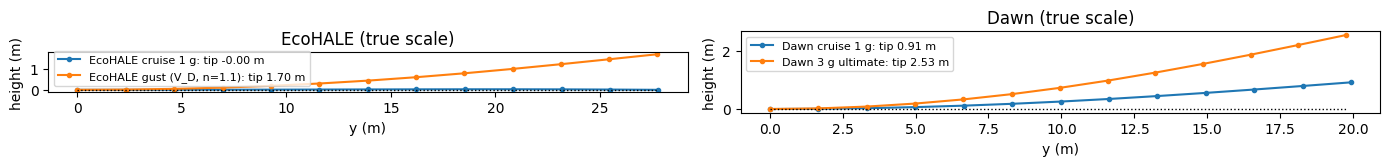

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for a_, keys in [(ax[0], ["EcoHALE cruise 1 g", "EcoHALE gust (V_D, n=1.1)"]), (ax[1], ["Dawn cruise 1 g", "Dawn 3 g ultimate"])]:
    for k in keys:
        c = cases[k]; p = np.asarray(gx.node_positions(c["model"], c["x"]))
        a_.plot(p[:, 1], -p[:, 2], "o-", ms=3, label=f"{k}: tip {c['tip']:.2f} m")
    a_.plot(p[:, 1], 0 * p[:, 1], "k:", lw=1)
    a_.set_aspect("equal"); a_.set_xlabel("y (m)"); a_.set_ylabel("height (m)"); a_.legend(fontsize=8)
ax[0].set_title("EcoHALE (true scale)"); ax[1].set_title("Dawn (true scale)"); plt.tight_layout()

## 4. Level-flight (1 g) flutter boundary
At each speed the half-wing is **re-trimmed** (root incidence by Newton, AD through the nonlinear equilibrium) so that lift balances weight, the
system is linearised about that deformed equilibrium, and the least-stable mode below 20 Hz is tracked. This is the flutter check that matters in
flight: the wing carries 1 g at every speed, so its static deformation stays realistic (contrary to a fixed-incidence sweep, in which the lift —
and the deflection — grows like V² until the wing is bent far beyond its strength).

Reference speeds: EcoHALE $V_D = 48.3$ m/s (its gust point); Dawn $V_D \approx \sqrt{2}\,V_{cruise} = 43$ m/s (`q_ne_over_q_max = 2` in `design_opt.py`).

Scans start at the cruise speed (below it, linear strip theory would need unrealistic incidences) and go to about 3 × $V_D$; each trim is warm-started from the previous speed. In-plane (lag) modes receive no aerodynamic damping in strip theory, so a least-stable Re(s) ≈ 0 means *neutral lag mode*, not flutter.

In [7]:
def level_flight_point(w, x, V, alpha0=0.05):
    root = w.root_carried_mass if isinstance(w, EcoHALEWing) else w.root_carried_mass(x)
    a, xs = trim_alpha(lambda al: w.build(x, V=V, alpha=al), root, alpha0=alpha0)
    m, f = w.build(x, V=V, alpha=a)
    r = gx.modal_analysis(m, f, xs)
    i = r.oscillatory(); i = i[r.freq_hz[i] < 20.0]
    g = r.eigvals.real[i] - 1e-6 * np.abs(r.eigvals[i])
    j = i[np.argmax(g)]
    return dict(V=V, alpha=a, growth=float(r.damping[j]), f=float(r.freq_hz[j]), tip=-float(gx.tip_displacement(m, xs)[2]))

def level_flight_scan(w, x, Vs):
    pts, a = [], 0.05
    for V in Vs:  # continuation: warm-start each trim from the previous speed
        pts.append(level_flight_point(w, x, V, a)); a = pts[-1]["alpha"]
    Vf = np.nan
    for p0, p1 in zip(pts[:-1], pts[1:]):
        if p0["growth"] <= 0 < p1["growth"]:
            Vf = p0["V"] + (p1["V"] - p0["V"]) * (-p0["growth"]) / (p1["growth"] - p0["growth"])
            break
    return pts, Vf

scan = {}
for name, w, x, Vs in [("EcoHALE", eco, x_eco, np.arange(35.0, 146.0, 10.0)), ("Dawn", dawn, t_dawn, np.arange(30.0, 131.0, 10.0))]:
    t = time.time(); pts, Vf = level_flight_scan(w, x, Vs); scan[name] = (pts, Vf)
    print(f"{name}: 1 g flutter speed = {Vf:.1f} m/s" if np.isfinite(Vf) else f"{name}: no 1 g flutter up to {Vs[-1]:.0f} m/s",
          f"({time.time() - t:.0f} s)")
    for p in pts:
        print(f"   V = {p['V']:5.0f} m/s  trim alpha {np.degrees(p['alpha']):6.2f} deg  tip {p['tip']:6.2f} m  "
              f"least-stable mode {p['f']:5.2f} Hz, Re(s)/2pi = {p['growth']:+.4f}")

EcoHALE: no 1 g flutter up to 145 m/s (35 s)
   V =    35 m/s  trim alpha   2.22 deg  tip  -0.00 m  least-stable mode 10.79 Hz, Re(s)/2pi = -0.0001
   V =    45 m/s  trim alpha  -2.63 deg  tip   0.00 m  least-stable mode 10.79 Hz, Re(s)/2pi = -0.0002
   V =    55 m/s  trim alpha  -5.07 deg  tip   0.01 m  least-stable mode 10.79 Hz, Re(s)/2pi = -0.0009
   V =    65 m/s  trim alpha  -6.47 deg  tip   0.01 m  least-stable mode 10.79 Hz, Re(s)/2pi = -0.0017
   V =    75 m/s  trim alpha  -7.36 deg  tip   0.01 m  least-stable mode 10.79 Hz, Re(s)/2pi = -0.0027
   V =    85 m/s  trim alpha  -7.95 deg  tip   0.02 m  least-stable mode  1.02 Hz, Re(s)/2pi = -0.0033
   V =    95 m/s  trim alpha  -8.37 deg  tip   0.03 m  least-stable mode  1.02 Hz, Re(s)/2pi = -0.0039
   V =   105 m/s  trim alpha  -8.67 deg  tip   0.03 m  least-stable mode  1.02 Hz, Re(s)/2pi = -0.0043
   V =   115 m/s  trim alpha  -8.90 deg  tip   0.04 m  least-stable mode  1.02 Hz, Re(s)/2pi = -0.0045
   V =   125 m/s  trim alpha

Dawn: no 1 g flutter up to 130 m/s (20 s)
   V =    30 m/s  trim alpha   4.38 deg  tip   0.92 m  least-stable mode  3.54 Hz, Re(s)/2pi = -0.0400
   V =    40 m/s  trim alpha  -0.12 deg  tip   0.89 m  least-stable mode  3.55 Hz, Re(s)/2pi = -0.0257
   V =    50 m/s  trim alpha  -2.18 deg  tip   0.85 m  least-stable mode  3.56 Hz, Re(s)/2pi = -0.0176
   V =    60 m/s  trim alpha  -3.30 deg  tip   0.81 m  least-stable mode  3.57 Hz, Re(s)/2pi = -0.0123
   V =    70 m/s  trim alpha  -3.98 deg  tip   0.75 m  least-stable mode  3.58 Hz, Re(s)/2pi = -0.0087
   V =    80 m/s  trim alpha  -4.41 deg  tip   0.69 m  least-stable mode  3.59 Hz, Re(s)/2pi = -0.0060
   V =    90 m/s  trim alpha  -4.70 deg  tip   0.61 m  least-stable mode  3.60 Hz, Re(s)/2pi = -0.0041
   V =   100 m/s  trim alpha  -4.91 deg  tip   0.51 m  least-stable mode  3.61 Hz, Re(s)/2pi = -0.0026
   V =   110 m/s  trim alpha  -5.06 deg  tip   0.40 m  least-stable mode  3.62 Hz, Re(s)/2pi = -0.0017
   V =   120 m/s  trim alpha  -

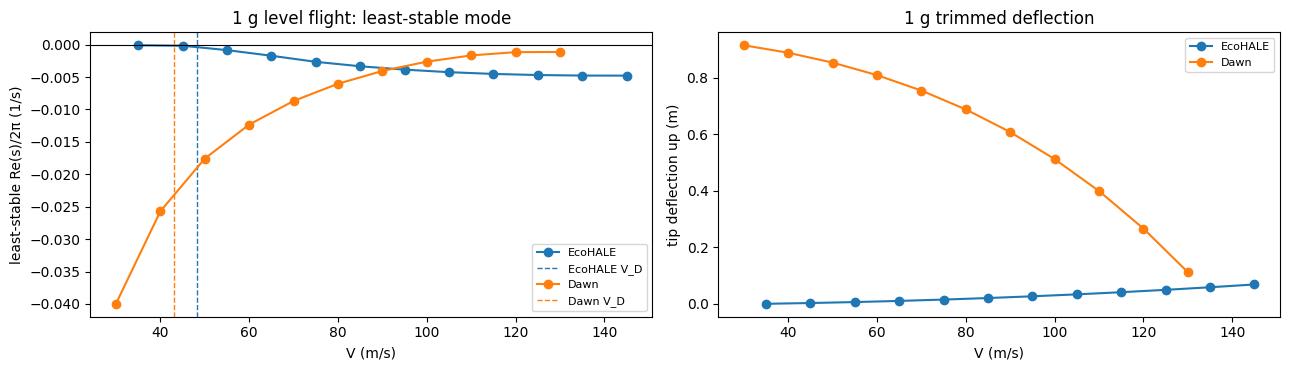

In [8]:
VD = {"EcoHALE": eco.V_DIVE, "Dawn": np.sqrt(2) * dawn.V_CRUISE}
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for i, name in enumerate(["EcoHALE", "Dawn"]):
    pts, Vf = scan[name]
    ax[0].plot([p["V"] for p in pts], [p["growth"] for p in pts], "o-", color=f"C{i}", label=name)
    ax[0].axvline(VD[name], color=f"C{i}", ls="--", lw=1, label=f"{name} V_D")
    ax[1].plot([p["V"] for p in pts], [p["tip"] for p in pts], "o-", color=f"C{i}", label=name)
ax[0].axhline(0, color="k", lw=0.8); ax[0].set_xlabel("V (m/s)"); ax[0].set_ylabel("least-stable Re(s)/2π (1/s)"); ax[0].legend(fontsize=8)
ax[0].set_title("1 g level flight: least-stable mode")
ax[1].set_xlabel("V (m/s)"); ax[1].set_ylabel("tip deflection up (m)"); ax[1].set_title("1 g trimmed deflection"); ax[1].legend(fontsize=8)
plt.tight_layout()

### Where should Dawn's batteries go?
DawnDesignTool sizes a 168 kg battery pack but its spar-mass model does not depend on *where* it sits. Moving it from the fuselage into the wing
(distributed with the chord, CG at 30 % chord on the spar) relieves the bending load — and changes the dynamics. Same spar.

In [9]:
dawn_w = DawnWing(12, batteries="wing")
for name, w in [("batteries in fuselage", dawn), ("batteries in the wing", dawn_w)]:
    c1 = solve_case(w, t_dawn, w.V_CRUISE); c3 = solve_case(w, t_dawn, np.sqrt(3) * w.V_CRUISE, n=3.0)
    mw, fw = w.build(t_dawn, aero=gx.Aero.NONE); f1 = gx.modal_analysis(mw, fw).table(1)[0, 1]
    pD = level_flight_point(w, t_dawn, VD["Dawn"])
    print(f"{name:24s} 1st mode {f1:.3f} Hz | tip at 1 g {c1['tip']:.2f} m, at 3 g {c3['tip']:.2f} m | root M_x at 3 g {c3['Mroot'] / 1e3:6.1f} kN m"
          f" | at V_D (1 g): least-stable {pD['f']:.2f} Hz, Re(s)/2pi = {pD['growth']:+.3f}")

batteries in fuselage    1st mode 0.725 Hz | tip at 1 g 0.91 m, at 3 g 2.53 m | root M_x at 3 g  -28.0 kN m | at V_D (1 g): least-stable 3.55 Hz, Re(s)/2pi = -0.023


batteries in the wing    1st mode 0.522 Hz | tip at 1 g 0.14 m, at 3 g 0.20 m | root M_x at 3 g   -5.0 kN m | at V_D (1 g): least-stable 2.60 Hz, Re(s)/2pi = -0.000


## 5. Gust encounter in the time domain (EcoHALE at cruise)
A 1−cos vertical gust of 3.4 m/s (EcoHALE's gust amplitude) and 30 m gradient length hits the trimmed wing; the nonlinear beam + Peters inflow is
integrated with generalised-α. The gust is applied through the vertical velocity of frame *a* (z down, so a negative value is an up-gust).

simulated 600 steps in 13 s


peak tip deflection 1.54 m -> -1.29 m; root moment -12.32 .. 8.24 kN m (1 g: -1.09)


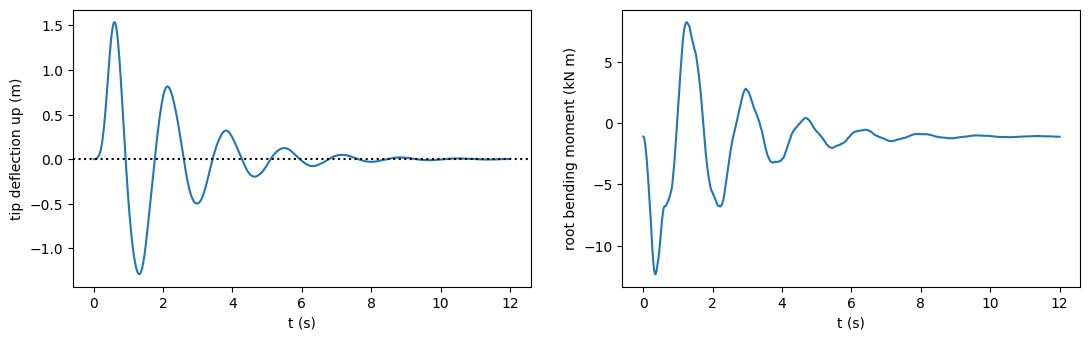

In [10]:
c0 = cases["EcoHALE cruise 1 g"]
L_g = 30.0; T_g = L_g / eco.V_CRUISE
def gust(t, fl, w0=eco.GUST, T=T_g):
    return fl.replace(v_a=jnp.array([0.0, 0.0, jnp.where(t < T, 0.5 * w0 * (1 - jnp.cos(2 * jnp.pi * t / T)), 0.0)]))
t0 = time.time()
h = gx.simulate(c0["model"], c0["flight"], t_end=12.0, dt=0.02, x0=c0["x"], flight_fn=gust)
print(f"simulated {len(h.t) - 1} steps in {time.time() - t0:.0f} s")
Mx = np.array([float(gx.split_state(c0["model"], jnp.asarray(xx))[0][3]) for xx in h.x])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(h.t, -h.tip()[:, 2]); ax[0].axhline(c0["tip"], color="k", ls=":"); ax[0].set_xlabel("t (s)"); ax[0].set_ylabel("tip deflection up (m)")
ax[1].plot(h.t, Mx / 1e3); ax[1].set_xlabel("t (s)"); ax[1].set_ylabel("root bending moment (kN m)")
print(f"peak tip deflection {-(h.tip()[:, 2]).min():.2f} m -> {-(h.tip()[:, 2]).max():.2f} m; root moment {Mx.min() / 1e3:.2f} .. {Mx.max() / 1e3:.2f} kN m "
      f"(1 g: {c0['Mroot'] / 1e3:.2f})")

## 6. Adjoint aeroelastic re-distribution of the EcoHALE wingbox
EcoHALE limits the tip deflection at its gust point (15 % of the half-span in the AeroSandbox notebook) and sizes the walls for buckling and stress.
Keeping its structural mass (82.4 kg), how much can a different *distribution* of skin and spar thickness reduce that deflection — computed here
with the geometrically exact beam — without degrading the flutter behaviour?

$$\min_{\mathbf t}\ w_{tip}^{\,gust}(\mathbf t)\quad\text{s.t.}\quad m_{box}(\mathbf t) = 82.4\ \text{kg},\quad V_f(\mathbf t)\ \ge\ V_f(\mathbf t_0),\quad 1 \le t \le 10\ \text{mm}\quad (24\ \text{variables}),$$

with $V_f$ the flutter speed of the wing deformed at the cruise-trim incidence (a stiffness/inertia margin metric whose gradient goes through
the implicitly differentiated equilibrium).

* $dw_{tip}/d\mathbf t$: `jax.grad` through the nonlinear static solve (one adjoint solve).
* $dV_f/d\mathbf t$: eigenvalue adjoint through the **deformed** equilibrium (`flutter_speed_and_grad(..., deformed=True)`).
* Buckling and stress are **not** modelled here: the result shows what redistribution can buy, not a new certified design.

In [11]:
build_fl = lambda x, V: eco.build(x, V=V, alpha=a_e)
a_g = a_e + np.arctan(eco.GUST / eco.V_DIVE)
def gust_tip(x):
    m, f = eco.build(x, V=eco.V_DIVE, alpha=a_g, gravity=1.1 * G0)
    return -gx.tip_displacement(m, gx.solve_static(m, f, n_load_steps=4))[2]
gust_vg = jax.value_and_grad(gust_tip)
mass_f = jax.jit(eco.structural_mass); dmass_f = jax.jit(jax.grad(eco.structural_mass))
cache, hist = {}, []
state = {"V": gx.flutter_speed(*eco.build(x_eco, alpha=a_e), 5.0, 200.0, n_grid=20, fmax_hz=20.0, n_load_steps=3).velocity}

def evaluate(z):
    key = tuple(np.round(z, 10))
    if key not in cache:
        t = time.time(); x = jnp.asarray(z * 1e-3); Vg = state["V"]
        r = gx.flutter_speed_and_grad(build_fl, x, 0.8 * Vg, 1.3 * Vg, n_grid=4, fmax_hz=20.0, deformed=True, tol=1e-5)
        if not r.point.found:
            r = gx.flutter_speed_and_grad(build_fl, x, 10.0, 150.0, n_grid=15, fmax_hz=20.0, deformed=True, tol=1e-5)
        state["V"] = r.point.velocity
        wt, dwt = gust_vg(x)
        cache[key] = dict(V=r.point.velocity, f=r.point.frequency_hz, dV=np.asarray(r.dV_dparams) * 1e-3, w=float(wt),
                          dw=np.asarray(dwt) * 1e-3, mass=float(mass_f(x)), time=time.time() - t)
        hist.append(cache[key])
    return cache[key]

z0 = np.asarray(x_eco) * 1e3
V0 = evaluate(z0)["V"]
cons = [{"type": "eq", "fun": lambda z: float(mass_f(jnp.asarray(z * 1e-3))) / 82.4 - 1,
         "jac": lambda z: np.asarray(dmass_f(jnp.asarray(z * 1e-3))) * 1e-3 / 82.4},
        {"type": "ineq", "fun": lambda z: evaluate(z)["V"] / V0 - 1, "jac": lambda z: evaluate(z)["dV"] / V0}]
t0 = time.time()
opt = scipy.optimize.minimize(lambda z: evaluate(z)["w"], z0, jac=lambda z: evaluate(z)["dw"], constraints=cons,
                              bounds=[(1.0, 10.0)] * (2 * eco.n), method="SLSQP", options={"maxiter": 15, "ftol": 1e-6})
ev0, ev = evaluate(z0), evaluate(opt.x)
print(opt.message, f"| {opt.nit} iterations, {len(hist)} evaluations, {(time.time() - t0) / 60:.1f} min")
print(f"gust-point tip deflection: {ev0['w']:.3f} -> {ev['w']:.3f} m  ({100 * (ev['w'] / ev0['w'] - 1):+.1f} %),"
      f" i.e. {100 * ev0['w'] / (eco.SPAN / 2):.1f} -> {100 * ev['w'] / (eco.SPAN / 2):.1f} % of the half-span")
print(f"flutter speed (cruise-trim incidence): {ev0['V']:.2f} -> {ev['V']:.2f} m/s;  wingbox mass {ev0['mass']:.2f} -> {ev['mass']:.2f} kg")

Iteration limit reached | 15 iterations, 16 evaluations, 0.9 min
gust-point tip deflection: 1.700 -> 1.689 m  (-0.7 %), i.e. 6.1 -> 6.1 % of the half-span
flutter speed (cruise-trim incidence): 113.23 -> 114.74 m/s;  wingbox mass 82.40 -> 82.40 kg


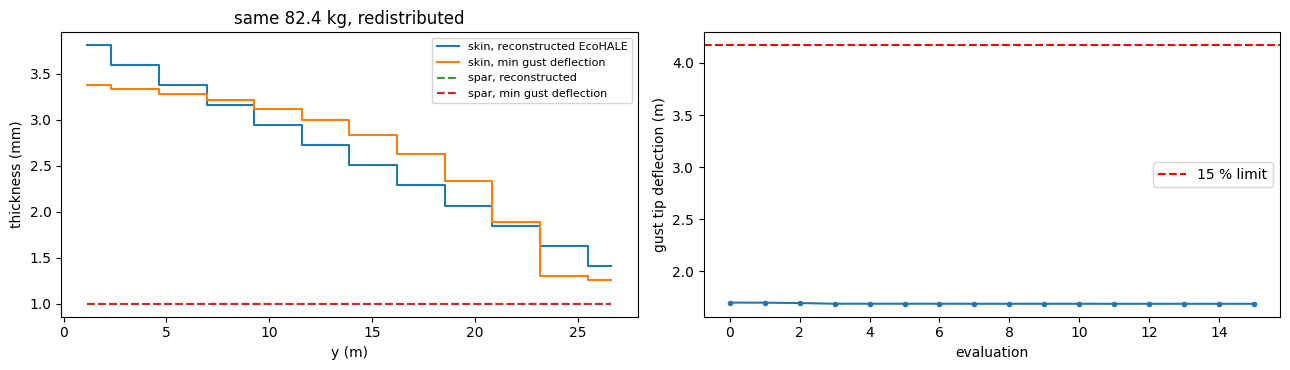

In [12]:
y = eco.eta * eco.SPAN / 2
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].step(y, z0[:eco.n], where="mid", label="skin, reconstructed EcoHALE"); ax[0].step(y, opt.x[:eco.n], where="mid", label="skin, min gust deflection")
ax[0].step(y, z0[eco.n:], where="mid", ls="--", label="spar, reconstructed"); ax[0].step(y, opt.x[eco.n:], where="mid", ls="--", label="spar, min gust deflection")
ax[0].set_xlabel("y (m)"); ax[0].set_ylabel("thickness (mm)"); ax[0].legend(fontsize=8); ax[0].set_title("same 82.4 kg, redistributed")
ax[1].plot([h["w"] for h in hist], "o-", ms=3); ax[1].set_xlabel("evaluation"); ax[1].set_ylabel("gust tip deflection (m)")
ax[1].axhline(0.15 * eco.SPAN / 2, color="r", ls="--", label="15 % limit"); ax[1].legend(); plt.tight_layout()

## Summary
* Both reconstructed designs close their published mass budgets. EcoHALE's span-loaded PV/batteries (and tip motors) nearly cancel the lift
  bending at 1 g; Dawn, with its battery pack in the fuselage, bends about 0.9 m at 1 g and 2.5 m at 3 g, where the small-deflection (linear)
  estimate overpredicts the geometrically exact deflection by about 30 %.
* In 1 g level flight (re-trimmed at every speed), **neither wing flutters up to about 3 × its dive speed** (EcoHALE: none up to 145 m/s,
  V_D = 48 m/s; Dawn: none up to 130 m/s, V_D ≈ 43 m/s). Dawn's least-stable mode (≈ 3.6 Hz) loses damping steadily with speed; EcoHALE's is
  essentially a neutral in-plane mode. Neither design tool computes this check; for wings this flexible it belongs in their sizing loops,
  together with the flight-dynamic (rigid-body) coupling not modelled here.
* For Dawn, moving the batteries into the wing removes most of the 3 g root bending moment and deflection, at the price of a lower first bending
  frequency — a trade the spar-*mass* model of the design tool cannot see.
* Exact gradients through the nonlinear equilibrium (implicit differentiation) and the flutter eigenproblem (eigen-adjoint) drive a 24-variable
  redistribution of EcoHALE's walls at constant structural mass in under a minute (§6). The gain is small (gust deflection −0.7 %, flutter speed
  +1.3 %): with the spars at their 1 mm bound and the material in the skins, the reconstructed EcoHALE distribution is already close to the
  stiffest one for its mass — a useful check of the reconstruction rather than a design improvement.

**Limits.** Reconstructed stiffness/mass distributions (assumptions in `examples/hale_wings.py`; EcoHALE t/c calibrated on one published
deflection), strip aerodynamics (no tip loss, no VLM), wing-alone cantilever (no rigid-body/flight-dynamic coupling — important for very
flexible HALE aircraft, cf. the Helios mishap), no buckling/stress constraints in §6.